In [1]:
import torch
import torch.nn as nn
import numpy as np
import scipy.io
from matplotlib import pyplot as plt
import matplotlib.animation as animation

## Generating Data

In [2]:
# Define the coordinates for the square's corners
x_min, y_min = 0, 0  # Lower-left corner
x_max, y_max = 1.0, 1.0  # Upper-right corner for a square with side length 1
t_min, t_max = 0, 20

In [3]:
##Generating Data
a=0.1
gamma=1
beta=0.5
eps=0.01
delta=0.0


dx=0.5
dt=0.1

diff = 0.5 ## diffusion coefficient
endtime=200 ## length of simulation in physical time units
nend=int(np.ceil(endtime/dt)) ## length of simulation in time steps
# outputevery=5  ##save u variable for display every this many time units
# nout=np.ceil(endtime/outputevery) ##number of times to output
# kout=1 ##index for output
nx = 100 ##2d square length in gridpoints; physical length is nx * dx


u=np.zeros((nx,nx), dtype= float); ##fast "voltage"-like variable
v=np.zeros((nx,nx), dtype=float); ##slow recovery variable
print(u.shape, v.shape, np.arange(np.ceil(nx/2), dtype = int).shape)


# u[0:25, 0:25] = 0.5



(100, 100) (100, 100) (50,)


In [4]:
radius = nx // 4

for i in range(nx):
    for j in range(nx):
        if i**2 + j**2 <= radius**2:
            u[i, j] = 0.5

In [5]:
radius = nx // 4

x = np.arange(nx)
y = np.arange(nx)
X, Y = np.meshgrid(x, y, indexing='ij')

mask = X**2 + Y**2 <= radius**2
u[mask] = 0.5

In [6]:
v1=v.copy()
u1 =u.copy()
training_points = np.zeros((100,100,100))
training_points_v = np.zeros((100,100,100))

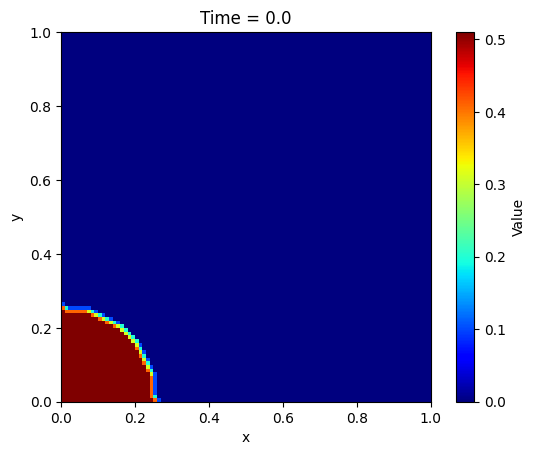

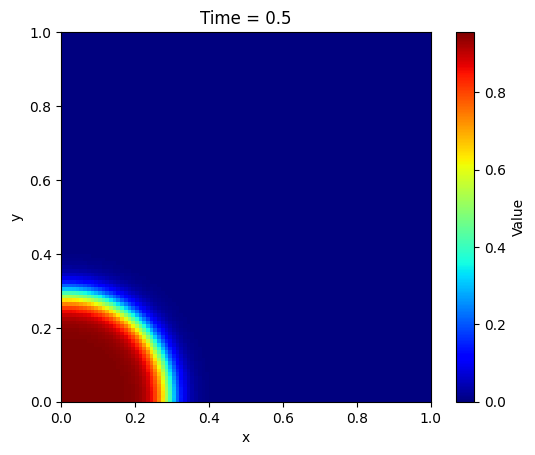

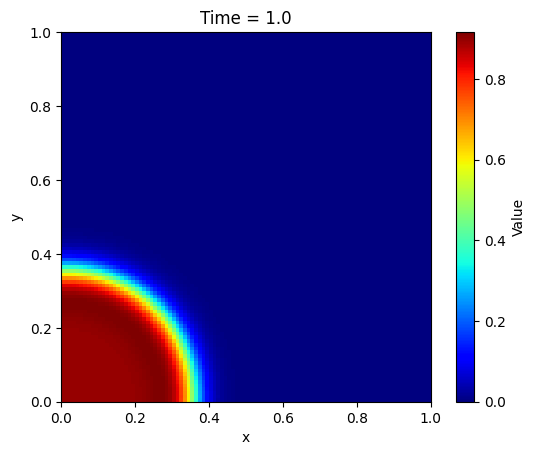

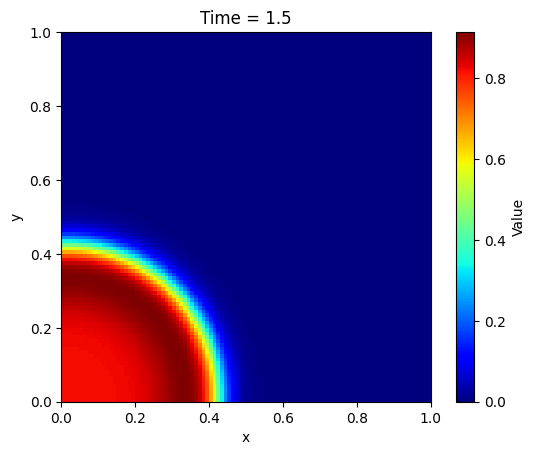

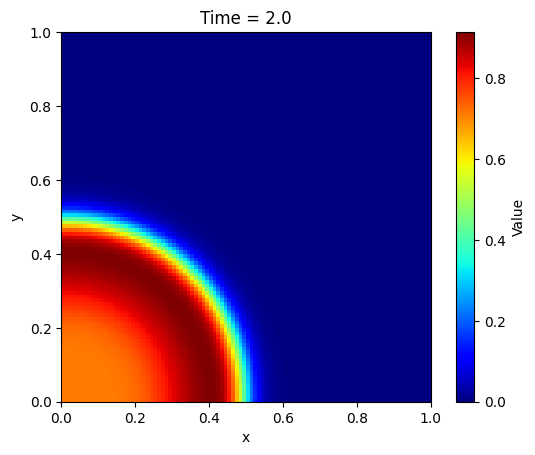

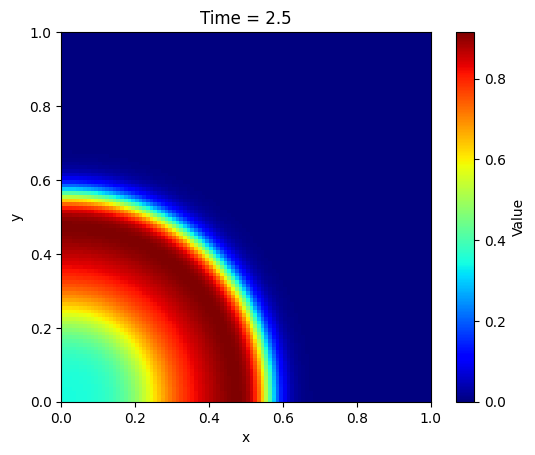

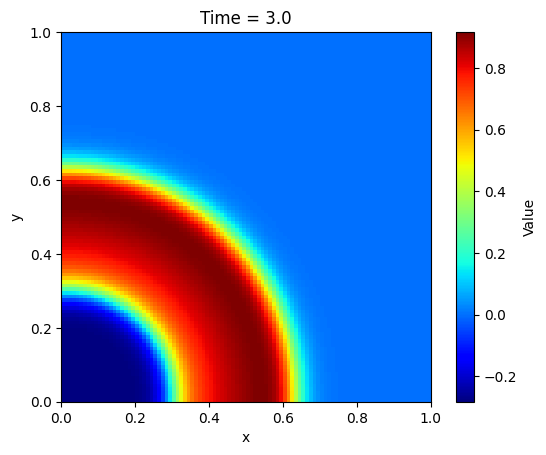

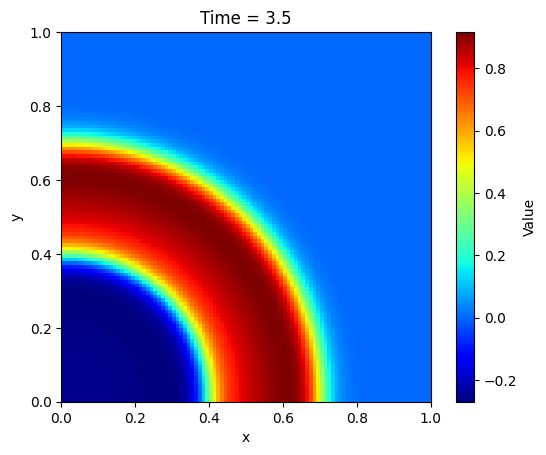

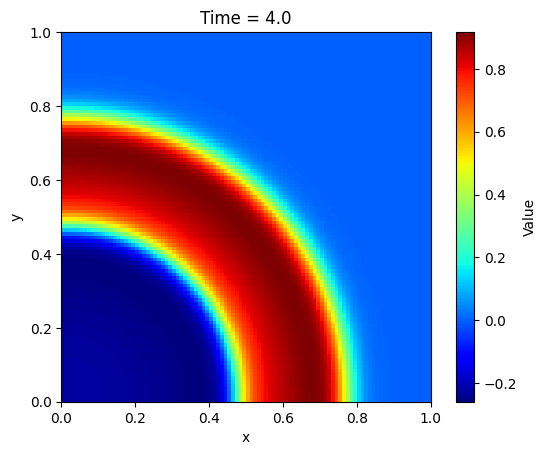

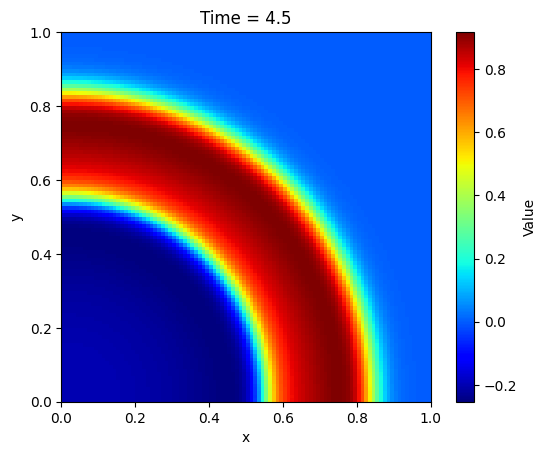

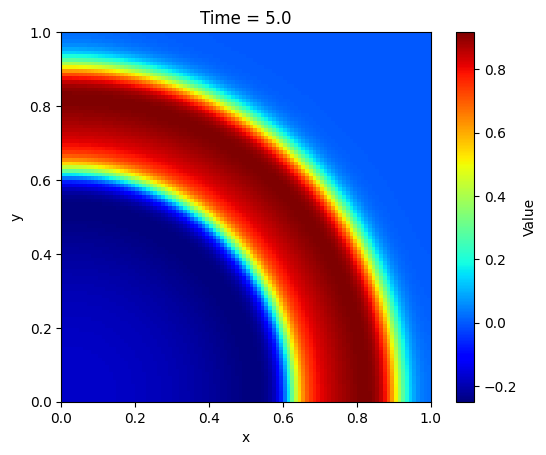

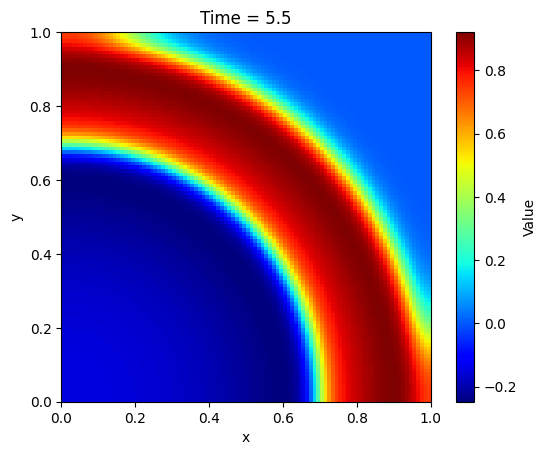

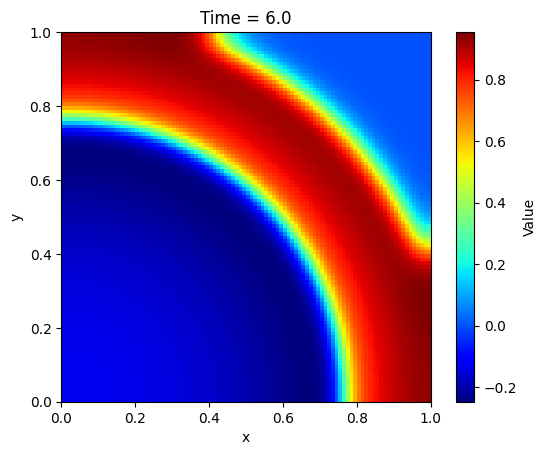

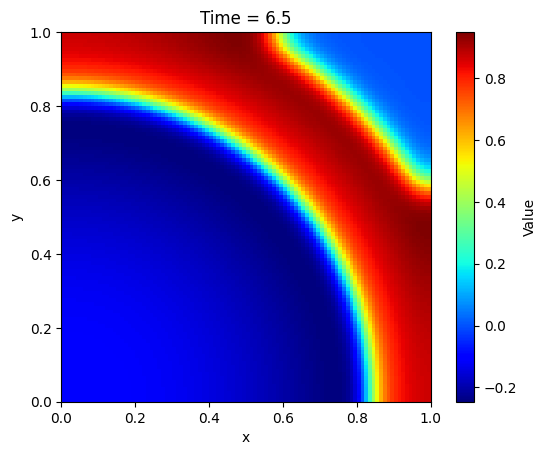

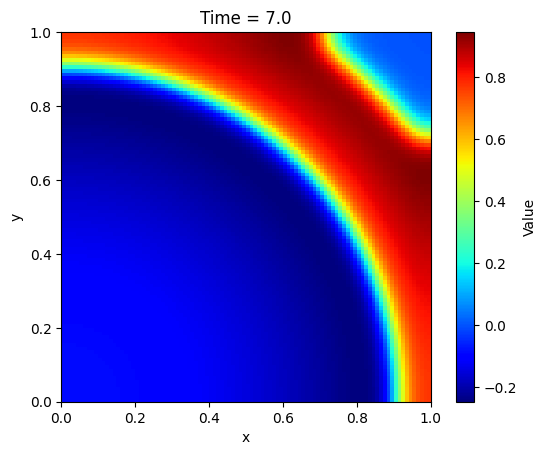

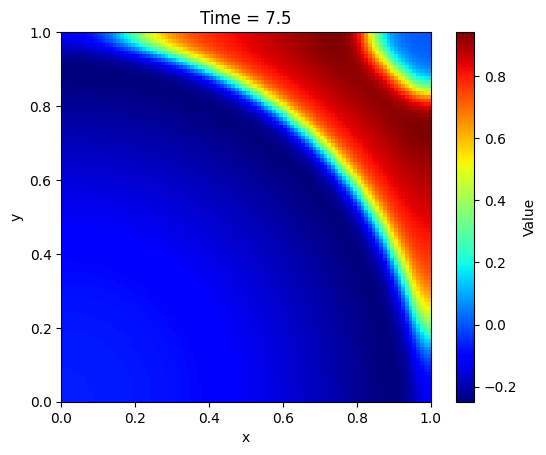

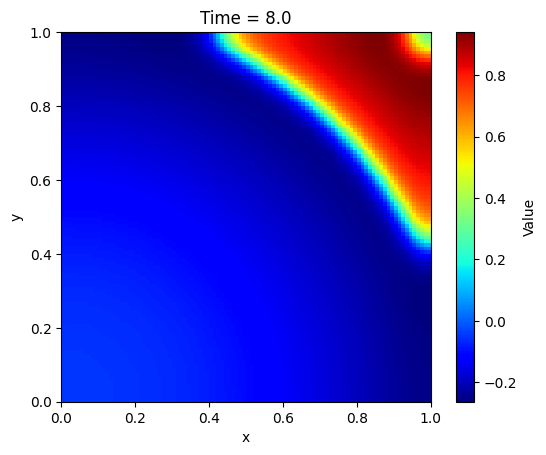

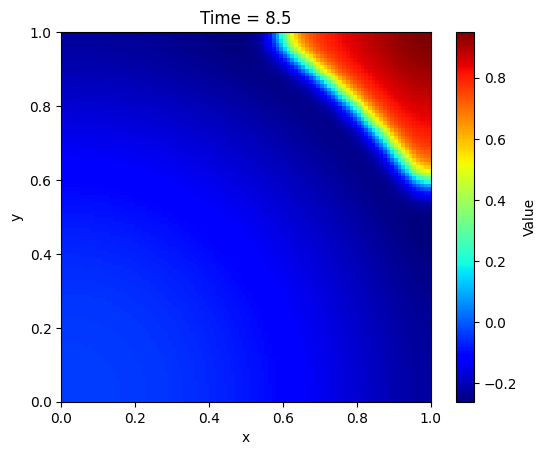

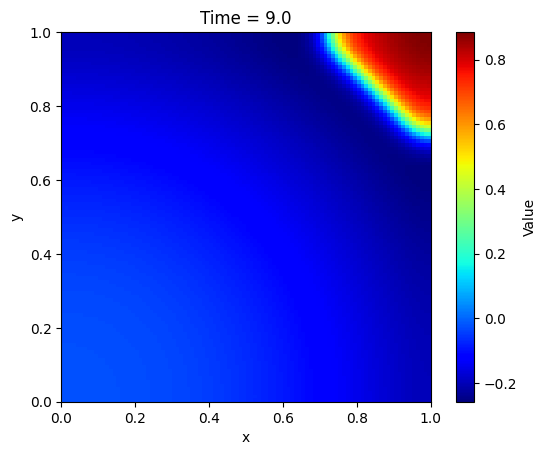

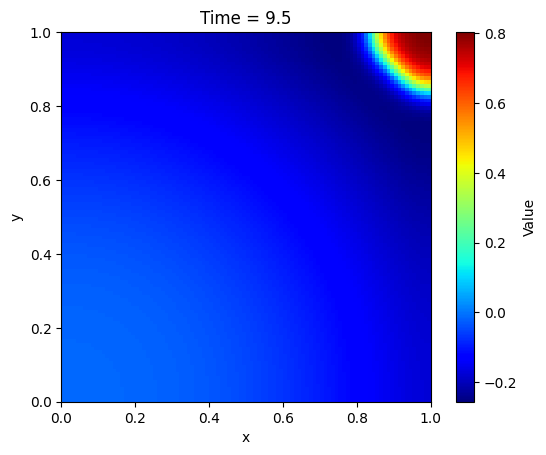

In [7]:
## Generating data
for ntime in range(nend): # 500 is the number of timesteps

    uold = u1.copy()
    vold = v1.copy()
    dv1 = eps*(beta*uold - gamma*vold -delta)
    du1 = (a-uold)*(uold-1)*uold-vold


    diff_x = np.zeros((nx, nx), dtype = float)
    diff_y = np.zeros((nx, nx), dtype = float)
    diff_x[0, :] = 2*(uold[2, :] - uold[1, :])
    diff_x[nx-1, :] = 2*(-uold[nx-1, :] + uold[nx-2, :])
    diff_x[1:-1, :] = uold[0:-2, :] - 2*uold[1:-1, :] + uold[2:, :]

    diff_y[:, 0] = 2*(uold[:, 2]-uold[:, 1])
    diff_y[:, nx-1] = 2*(-uold[:, nx-1] + uold[:, nx-2])
    diff_y[:, 1:-1] = uold[:, 0:-2] -2*uold[:, 1:-1] + uold[:, 2:]

    u1 = uold + dt*du1 + diff*dt/(dx*dx)*(diff_x+diff_y)
    v1 = vold +  dt*dv1

    if (ntime % 20 == 0):
        training_points[int(ntime/20),:, :] = u1.T
        training_points_v[int(ntime/20),:, :] = v1.T

        # plt.figure()
        # plt.imshow(u1, cmap='copper', origin='lower', extent=[x_min, x_max, y_min, y_max], vmin=-0.3, vmax=1)
        # plt.colorbar()
        # plt.title(f'Time = {ntime * dt}')
        # plt.draw()
        # plt.pause(0.001)  # Equivalent of MATLAB's drawnow
        # plt.show()
    if (ntime % 100 == 0):
        plt.figure()
        plt.imshow(u1, cmap='jet', origin='lower', extent=[0, 1, 0, 1])
        plt.colorbar(label='Value')  # Add a colorbar
        plt.title(f'Time = {ntime * 0.005}')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.show()

In [8]:
## Constants
a=0.1
gamma=1
beta=0.5
eps=0.01
delta=0

In [25]:

class FitzHughNagumo():
    def __init__(self, ic_pts, bc_pts, data_pts, res_pts):


        ## TODO : Add boundary condition loss for v?

        self.x_data = torch.tensor(data_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_data = torch.tensor(data_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_data = torch.tensor(data_pts[2], requires_grad=True, dtype=torch.float32)

        self.u_gt = torch.tensor(data_pts[3], requires_grad=True, dtype=torch.float32)
        self.v_gt = torch.tensor(data_pts[4], requires_grad=True, dtype=torch.float32)

        self.x_left = torch.tensor(bc_pts['left'][0], requires_grad=True, dtype=torch.float32)
        self.y_left = torch.tensor(bc_pts['left'][1], requires_grad=True, dtype=torch.float32)
        self.t_left = torch.tensor(bc_pts['left'][2], requires_grad=True, dtype=torch.float32)

        self.x_right = torch.tensor(bc_pts['right'][0], requires_grad=True, dtype=torch.float32)
        self.y_right = torch.tensor(bc_pts['right'][1], requires_grad=True, dtype=torch.float32)
        self.t_right = torch.tensor(bc_pts['right'][2], requires_grad=True, dtype=torch.float32)

        self.x_top = torch.tensor(bc_pts['top'][0], requires_grad=True, dtype=torch.float32)
        self.y_top = torch.tensor(bc_pts['top'][1], requires_grad=True, dtype=torch.float32)
        self.t_top = torch.tensor(bc_pts['top'][2], requires_grad=True, dtype=torch.float32)

        self.x_bottom = torch.tensor(bc_pts['bottom'][0], requires_grad=True, dtype=torch.float32)
        self.y_bottom = torch.tensor(bc_pts['bottom'][1], requires_grad=True, dtype=torch.float32)
        self.t_bottom = torch.tensor(bc_pts['bottom'][2], requires_grad=True, dtype=torch.float32)

        self.x_ic = torch.tensor(ic_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_ic = torch.tensor(ic_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_ic = torch.tensor(ic_pts[2], requires_grad=True, dtype=torch.float32)
        self.u_ic = torch.tensor(ic_pts[3], requires_grad=True, dtype=torch.float32)
        self.v_ic = torch.tensor(ic_pts[4], requires_grad=True, dtype=torch.float32)
        
        self.x_res = torch.tensor(res_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_res = torch.tensor(res_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_res = torch.tensor(res_pts[2], requires_grad=True, dtype=torch.float32)
        
        
        
        
        self.data_losses = []
        self.pde_losses = []
        self.bc_losses = []
        self.ic_losses = []
        
        self.losses = [] 




        # initialize network:
        self.network()

        self.optimizer_adam = torch.optim.Adam(self.net.parameters(), lr = 1e-3)

        self.optimizer = torch.optim.LBFGS(self.net.parameters(), lr=0.1, max_iter=200000, max_eval=50000,
                                           history_size=50, tolerance_grad=1e-05, tolerance_change=0.5 * np.finfo(float).eps,
                                           line_search_fn="strong_wolfe")

        self.mse = nn.MSELoss()

        #loss
        self.ls = 0

        #iteration number
        self.iter = 0

    def network(self):

         self.net = nn.Sequential(
            nn.Linear(3, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 2))

    def function(self, x, y, t):

        res = self.net(torch.hstack((x, y, t)))
        u, v = res[:, 0:1], res[:, 1:2]


        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        v_t = torch.autograd.grad(v, t, grad_outputs=torch.ones_like(v), create_graph=True)[0]

        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
        
        u_y = torch.autograd.grad(u, y, torch.ones_like(u), create_graph=True)[0]
        u_yy = torch.autograd.grad(u_y, y, torch.ones_like(u_y), create_graph=True)[0]

        f = u_t - (u_xx + u_yy + (a - u)*(u - 1)*u - v)

        g = v_t - (eps*(beta*u - gamma*v - delta))

        return u, v, f, g

    def closure(self):

        # reset gradients to zero:
        self.optimizer_adam.zero_grad()
        self.optimizer.zero_grad()

        # --- PDE & DATA LOSS ---
        u_data, v_data, _, _ = self.function(self.x_data, self.y_data, self.t_data)
        
        _, _, f_res, g_res = self.function(self.x_res, self.y_res, self.t_res)

        loss_pde = self.mse(f_res, torch.zeros_like(f_res)) + self.mse(g_res, torch.zeros_like(g_res))
        loss_data = self.mse(u_data, self.u_gt) + self.mse(v_data, self.v_gt)

        # --- INITIAL CONDITION LOSS ---
        res_ic = self.net(torch.hstack((self.x_ic, self.y_ic, self.t_ic)))
        loss_ic = self.mse(res_ic[:,0:1], self.u_ic) + self.mse(res_ic[:,1:2], self.v_ic)

       # --- NEUMANN BOUNDARY LOSS (Zero Flux for u AND v) ---

        # LEFT (∂/∂x = 0)
        uv_left = self.net(torch.hstack((self.x_left, self.y_left, self.t_left)))
        u_left = uv_left[:, 0:1]
        v_left = uv_left[:, 1:2]

        du_dx_left = torch.autograd.grad(u_left, self.x_left, torch.ones_like(u_left), create_graph=True)[0]
        dv_dx_left = torch.autograd.grad(v_left, self.x_left, torch.ones_like(v_left), create_graph=True)[0]

        loss_bc_left = self.mse(du_dx_left, torch.zeros_like(du_dx_left)) + \
                       self.mse(dv_dx_left, torch.zeros_like(dv_dx_left))


        # RIGHT (∂/∂x = 0)
        uv_right = self.net(torch.hstack((self.x_right, self.y_right, self.t_right)))
        u_right = uv_right[:, 0:1]
        v_right = uv_right[:, 1:2]

        du_dx_right = torch.autograd.grad(u_right, self.x_right, torch.ones_like(u_right), create_graph=True)[0]
        dv_dx_right = torch.autograd.grad(v_right, self.x_right, torch.ones_like(v_right), create_graph=True)[0]

        loss_bc_right = self.mse(du_dx_right, torch.zeros_like(du_dx_right)) + \
                        self.mse(dv_dx_right, torch.zeros_like(dv_dx_right))


        # TOP (∂/∂y = 0)
        uv_top = self.net(torch.hstack((self.x_top, self.y_top, self.t_top)))
        u_top = uv_top[:, 0:1]
        v_top = uv_top[:, 1:2]

        du_dy_top = torch.autograd.grad(u_top, self.y_top, torch.ones_like(u_top), create_graph=True)[0]
        dv_dy_top = torch.autograd.grad(v_top, self.y_top, torch.ones_like(v_top), create_graph=True)[0]

        loss_bc_top = self.mse(du_dy_top, torch.zeros_like(du_dy_top)) + \
                      self.mse(dv_dy_top, torch.zeros_like(dv_dy_top))


        # BOTTOM (∂/∂y = 0)
        uv_bottom = self.net(torch.hstack((self.x_bottom, self.y_bottom, self.t_bottom)))
        u_bottom = uv_bottom[:, 0:1]
        v_bottom = uv_bottom[:, 1:2]

        du_dy_bottom = torch.autograd.grad(u_bottom, self.y_bottom, torch.ones_like(u_bottom), create_graph=True)[0]
        dv_dy_bottom = torch.autograd.grad(v_bottom, self.y_bottom, torch.ones_like(v_bottom), create_graph=True)[0]

        loss_bc_bottom = self.mse(du_dy_bottom, torch.zeros_like(du_dy_bottom)) + \
                         self.mse(dv_dy_bottom, torch.zeros_like(dv_dy_bottom))


        loss_bc = loss_bc_left + loss_bc_right + loss_bc_top + loss_bc_bottom




        
       

        
        self.ls = 1000*loss_pde + 1000*loss_data + loss_ic + 100*loss_bc
        
       
            
        
        self.pde_losses.append(loss_pde.item())
        self.data_losses.append(loss_data.item())
        self.ic_losses.append(loss_ic.item())
        self.bc_losses.append(loss_bc.item())
        self.losses.append(self.ls.item())

        # derivative with respect to net's weights:
       

        self.ls.backward()

        self.iter += 1
        if (self.iter % 100 == 0):
            print(loss_pde, loss_data, loss_ic, loss_bc)
            print(loss_bc_left, loss_bc_right, loss_bc_top, loss_bc_bottom)
        print(f'Iteration: {self.iter}, Loss: {self.ls.item():.6f}')

        return self.ls
    
    def resample_residual_points(self, num_samples=20000, alpha=1.0):
        # Compute residuals on pool
        _, _, f_res, g_res = self.function(self.x_pool, self.y_pool, self.t_pool)

        residual_squared = f_res**2 + g_res**2
        residual_squared = residual_squared.detach().flatten()

        # Convert to probability distribution
        prob = torch.softmax(alpha * residual_squared, dim=0)

        # Sample indices
        indices = torch.multinomial(prob, num_samples, replacement=True)

        # Update residual training points
        self.x_res = self.x_pool[indices].clone().detach().requires_grad_(True)
        self.y_res = self.y_pool[indices].clone().detach().requires_grad_(True)
        self.t_res = self.t_pool[indices].clone().detach().requires_grad_(True)
        
    def resample_pool_points(self, N_pool=50000, t_max=10.0):
        """
        Refreshes the candidate pool used for adaptive residual sampling.
        This should be called infrequently (e.g., every 5000+ iterations).
        """

        # Uniform sampling over full PDE domain
        self.x_pool = torch.rand(N_pool, 1, dtype=torch.float32, requires_grad=True)
        self.y_pool = torch.rand(N_pool, 1, dtype=torch.float32, requires_grad=True)
        self.t_pool = torch.rand(N_pool, 1, dtype=torch.float32, requires_grad=True) * t_max

    def train(self, adam_epochs=20000):
        self.net.train()

        for epoch in range(adam_epochs):
            loss = self.closure()
            self.optimizer_adam.step()
            
                
        def lbfgs_closure():
            return self.closure()

        self.optimizer.step(lbfgs_closure)

        


In [26]:

## define x,y,t,u and v
x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
t = np.linspace(0, 10, 100)



In [27]:
X, Y, T = np.meshgrid(y,x,t,indexing='xy')
x = X.ravel().reshape(1000000, 1)
y = Y.ravel().reshape(1000000, 1)
t = T.ravel().reshape(1000000, 1)

In [28]:
print((x == x_max))

[[False]
 [False]
 [False]
 ...
 [ True]
 [ True]
 [ True]]


In [29]:
u = np.zeros((1000000, 1))
v = np.zeros((1000000, 1))
count = 0
for i in range(100):
    for j in range(100):
        for k in range(100):
            # print(k,i,j)
            u[count] = training_points[k, j, i]
            v[count] = training_points_v[k, j, i]
            count += 1



In [30]:
mask_ic = (t == t_min).flatten()
mask_bc_left = ((x==x_min))
mask_bc_right = ((x==x_max))
mask_bc_top = ((y==y_max))
mask_bc_bottom = ((y==y_min))
mask_f = np.ones_like(mask_ic, dtype=bool)



In [31]:
def sample(x,y,t,u,v,mask, n_samples):
    # Get indices where mask is True
    indices = np.where(mask)[0]

    # Randomly pick n_samples indices without replacement
    sampled_indices = np.random.choice(indices, size=min(n_samples, len(indices)), replace=False)

    # Return the sliced data
    return x[sampled_indices], y[sampled_indices], t[sampled_indices], u[sampled_indices], v[sampled_indices]

# Suggested sample sizes for L-BFGS efficiency
N_ic = 2000
N_bc = 5000
N_data  = 1000
N_res = 20000
N_pool = 100000

x_ic, y_ic, t_ic, u_ic, v_ic = sample(x,y,t,u,v,mask_ic, N_ic)
x_bc_left, y_bc_left, t_bc_left, u_bc_left, v_bc_left = sample(x,y,t,u,v,mask_bc_left, N_bc)
x_bc_right, y_bc_right, t_bc_right, u_bc_right, v_bc_right = sample(x,y,t,u,v,mask_bc_right, N_bc)
x_bc_top, y_bc_top, t_bc_top, u_bc_top, v_bc_top = sample(x,y,t,u,v,mask_bc_top, N_bc)
x_bc_bottom, y_bc_bottom, t_bc_bottom, u_bc_bottom, v_bc_bottom = sample(x,y,t,u,v,mask_bc_bottom, N_bc)
x_data, y_data, t_data, u_data, v_data = sample(x,y,t,u,v,mask_f, N_data)

x_r = np.random.uniform(0, 1, (N_res, 1))
y_r = np.random.uniform(0, 1, (N_res, 1))
t_r = np.random.uniform(0, 10, (N_res, 1))


x_pool = np.random.uniform(0, 1, (N_pool, 1))
y_pool = np.random.uniform(0, 1, (N_pool, 1))
t_pool = np.random.uniform(0, 10, (N_pool, 1))

In [32]:
print(x_bc_right, y_bc_top)

[[1.]
 [1.]
 [1.]
 ...
 [1.]
 [1.]
 [1.]] [[1.]
 [1.]
 [1.]
 ...
 [1.]
 [1.]
 [1.]]


In [33]:
ic_pts = [x_ic, y_ic, t_ic, u_ic, v_ic]

bc_left = [x_bc_left, y_bc_left, t_bc_left]
bc_right = [x_bc_right, y_bc_right, t_bc_right]
bc_top = [x_bc_top, y_bc_top, t_bc_top]
bc_bottom = [x_bc_bottom, y_bc_bottom, t_bc_bottom]

bcs = [bc_left, bc_right, bc_top, bc_bottom]
bc_pts = {}
for i, item in enumerate(['left', 'right', 'top', 'bottom']):
  bc_pts[item] = bcs[i]

data_pts = [x_data, y_data, t_data, u_data, v_data]
res_pts = [x_r, y_r, t_r]





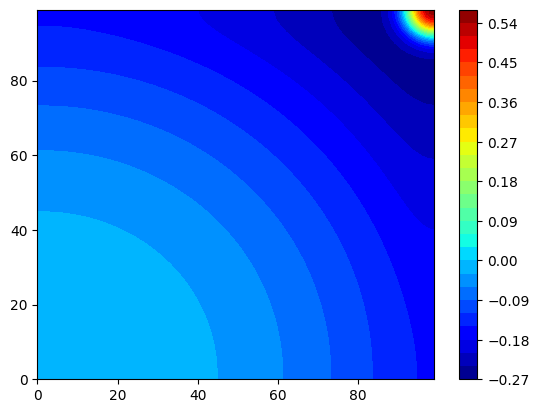

In [34]:

fig, ax = plt.subplots()
indices = np.where(np.isclose(t, 10))[0]
plt.contourf(u[indices].reshape(100,100), levels=30, cmap='jet')
plt.colorbar()

In [ ]:
pinn = FitzHughNagumo(ic_pts, bc_pts, data_pts, res_pts)

pinn.train()

torch.save(pinn.net.state_dict(), 'modelVanillaPINN.pt')

In [37]:
## Testing Data
idx = np.where(np.isclose(t, 2.020202))[0]
print(idx)
t_test = t[idx]
x_test = x[idx]
y_test = y[idx]

[    20    120    220 ... 999720 999820 999920]


IndexError: index 120 is out of bounds for axis 0 with size 100

In [38]:
print(t_test.shape)

(10000, 1)


/tmp/ipykernel_3612219/1523135487.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_test = torch.tensor(x_test, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_3612219/1523135487.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_test = torch.tensor(y_test, dtype=torch.float32, requires_grad=True)


Text(0, 0.5, 'y')

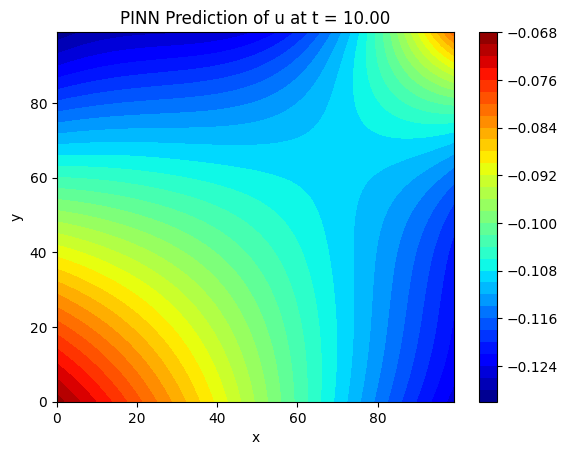

In [39]:
pinn2 = FitzHughNagumo(ic_pts, bc_pts, data_pts, res_pts)
pinn2.net.load_state_dict(torch.load('modelVanillaPINN.pt'))
pinn2.net.eval()

x_test = torch.tensor(x_test, dtype=torch.float32, requires_grad=True)
y_test = torch.tensor(y_test, dtype=torch.float32, requires_grad=True)
t_test = torch.tensor(np.full((10000,1), 10), dtype=torch.float32, requires_grad=True)

u_out, v_out, f_out, g_out = pinn2.function(x_test, y_test, t_test)


u_plot = u_out.data.cpu().numpy()
u_plot = np.reshape(u_plot, (100, 100))
time_val = t_test[0].item()
fig, ax = plt.subplots()

plt.contourf(u_plot, levels=30, cmap='jet')
plt.colorbar()

plt.title(f"PINN Prediction of u at t = {time_val:.2f}")
plt.xlabel("x")
plt.ylabel("y")



In [40]:
import imageio
import os

In [41]:
def generate_u_gif(
    pinn,
    x_flat,
    y_flat,
    t_min,
    t_max,
    Nt=50,
    filename="u_prediction.gif",
    levels=30,
    cmap="jet"
):
    """
    Generate a GIF of u(x,y,t) predicted by a trained PINN.

    Parameters
    ----------
    pinn : FitzHughNagumo
        Trained PINN model (with loaded weights)
    x_grid, y_grid : np.ndarray
        Meshgrid arrays of shape (Nx, Ny)
    t_min, t_max : float
        Time range
    Nt : int
        Number of time frames
    filename : str
        Output GIF filename
    """

    pinn.net.eval()

    Nx, Ny = 100,100
    frames = []

    for t_val in np.linspace(t_min, t_max, Nt):
        t_test = np.full((10000,1), t_val)
        t_flat = torch.tensor(t_test, dtype=torch.float32, requires_grad=True)


        u_pred, _, _, _ = pinn.function(x_flat, y_flat, t_flat)

        # Reshape to grid
        u_plot = u_pred.data.cpu().numpy().reshape(Nx, Ny)

        # Plot
        fig, ax = plt.subplots(figsize=(5, 4))
        vmin, vmax = -1.0, 1.5
        contour = ax.contourf(u_plot, levels=levels, cmap=cmap)
        ax.set_title(f"u(x,y,t), t = {t_val:.3f}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        fig.colorbar(contour)

        # Save frame to buffer
        fig.canvas.draw()
        buf = np.asarray(fig.canvas.buffer_rgba())
        image = buf[..., :3]
        frames.append(image)
        plt.close(fig)

    # Save GIF
    imageio.mimsave(filename, frames, fps=8)

    print(f"GIF saved to {filename}")


In [42]:
generate_u_gif(pinn2, x_test, y_test, 0, 20, 100, "u_prediction.gif", 30, "jet")

GIF saved to u_prediction.gif


In [ ]:
!pip install imageio

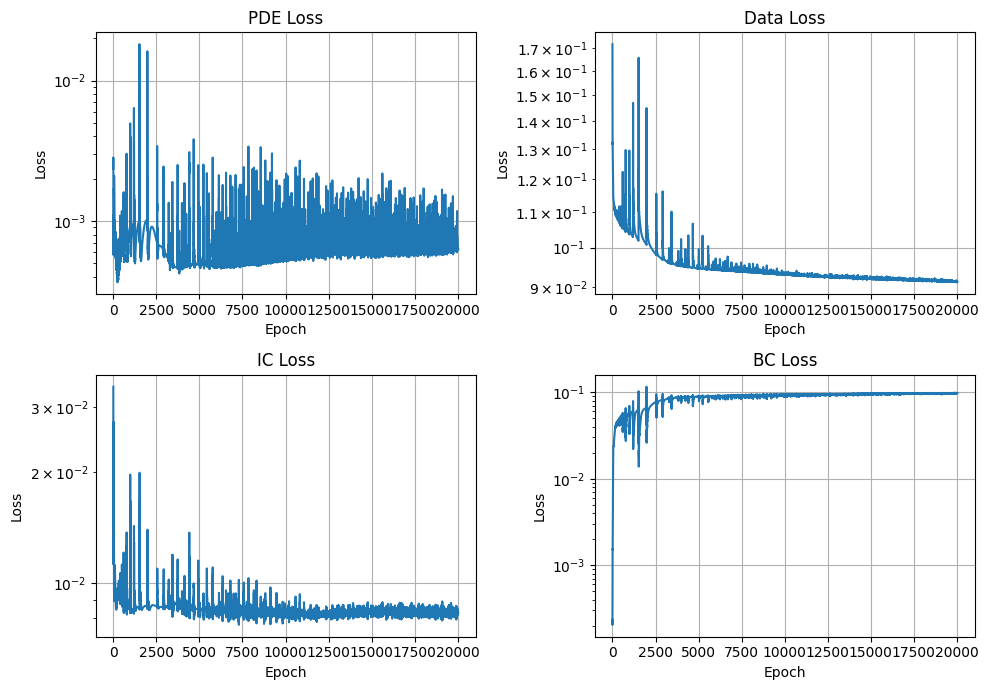

In [108]:
fig, axs = plt.subplots(2, 2, figsize=(10,7))

axs[0,0].plot(pinn.pde_losses)
axs[0,0].set_title("PDE Loss")
axs[0,0].set_yscale("log")

axs[0,1].plot(pinn.data_losses)
axs[0,1].set_title("Data Loss")
axs[0,1].set_yscale("log")

axs[1,0].plot(pinn.ic_losses)
axs[1,0].set_title("IC Loss")
axs[1,0].set_yscale("log")

axs[1,1].plot(pinn.bc_losses)
axs[1,1].set_title("BC Loss")
axs[1,1].set_yscale("log")

for ax in axs.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print(pinn.pde_losses)

Timestep t = 6.00
Relative L2 Error: 0.784971
RMSE: 0.416814
MAE: 0.381082
Accuracy (1 - rel L2): 0.215029


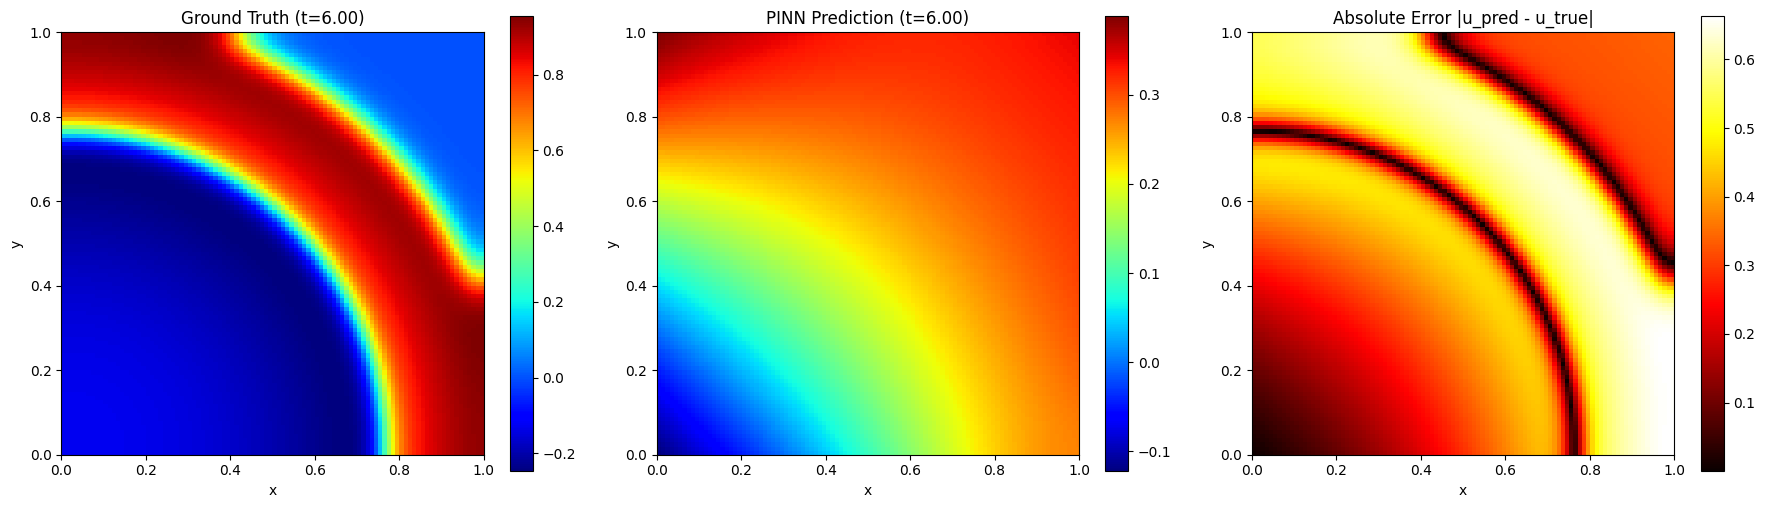

In [45]:
# choose timestep index
t_index = 60
time_val = t_index / 10

# ground truth
u_true = training_points[t_index, :, :]

# create grid
x = np.linspace(0,1,100)
y = np.linspace(0,1,100)
X, Y = np.meshgrid(x,y)

# flatten grid for PINN
x_test = torch.tensor(X.flatten()[:,None], dtype=torch.float32, requires_grad=True)
y_test = torch.tensor(Y.flatten()[:,None], dtype=torch.float32, requires_grad=True)
t_test = torch.tensor(np.full_like(X.flatten()[:,None], time_val), dtype=torch.float32, requires_grad=True)

# PINN prediction
u_out, v_out, f_out, g_out = pinn2.function(x_test, y_test, t_test)
u_pred = u_out.detach().cpu().numpy().reshape(100,100)

# error
error = np.abs(u_true - u_pred)

# ===== METRICS =====
# Relative L2 Error
rel_l2_error = np.linalg.norm(u_true - u_pred) / np.linalg.norm(u_true)

# RMSE
rmse = np.sqrt(np.mean((u_true - u_pred)**2))

# MAE
mae = np.mean(np.abs(u_true - u_pred))

# "Accuracy" (optional interpretation)
accuracy = 1 - rel_l2_error

print(f"Timestep t = {time_val:.2f}")
print(f"Relative L2 Error: {rel_l2_error:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"Accuracy (1 - rel L2): {accuracy:.6f}")

# ===== PLOTTING =====
fig, axs = plt.subplots(1,3, figsize=(18,5))

# ground truth
gt = axs[0].imshow(u_true, cmap='jet', origin='lower', extent=[0,1,0,1])
axs[0].set_title(f"Ground Truth (t={time_val:.2f})")
fig.colorbar(gt, ax=axs[0])

# prediction
pred = axs[1].imshow(u_pred, cmap='jet', origin='lower', extent=[0,1,0,1])
axs[1].set_title(f"PINN Prediction (t={time_val:.2f})")
fig.colorbar(pred, ax=axs[1])

# error
err = axs[2].imshow(error, cmap='hot', origin='lower', extent=[0,1,0,1])
axs[2].set_title("Absolute Error |u_pred - u_true|")
fig.colorbar(err, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()